Q3)

- Simulate linear regression, estimate model parameters, calculate errors, and visualize the results.
- Repeat the experiment using a different input matrix and investigate the effect of multicollinearity.
- Analyze and compare the results of the two experiments, including parameter distributions and correlations.



********************
Experiment 1
X.T @ X:
[[6. 5.]
 [5. 5.]]
Condition Number:
22.154863183232944
Theoretical Mean:
[0 1]
Theoretical Covariance:
[[ 1.  -1. ]
 [-1.   1.2]]
Empirical Mean:
[0.0192217  1.01283987]
Empirical Covariance:
[[ 0.79906792 -0.72436288]
 [-0.72436288  0.81143417]]
Mean Error:
1.083232220929129
Standard Deviation of Errors:
0.643201767309438
Correlation between w1 and w2:
-0.8995756498183543


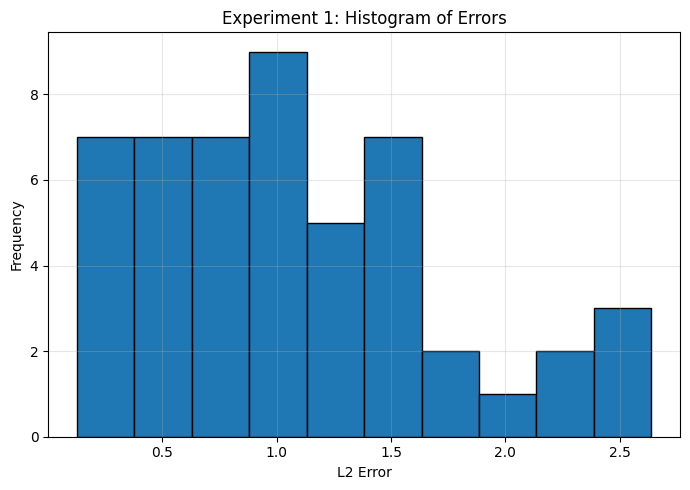

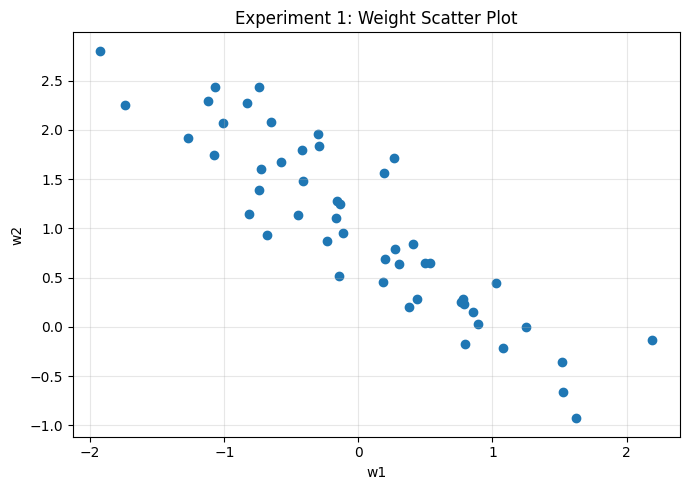

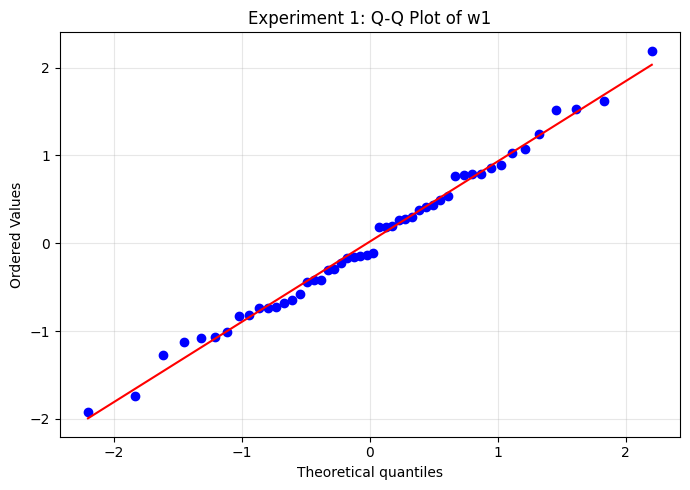

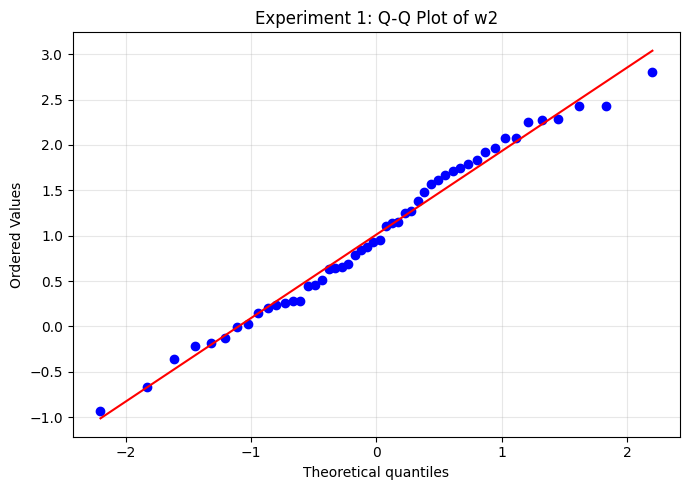


********************
Experiment 2
X.T @ X:
[[6.   6.2 ]
 [6.2  6.41]]
Condition Number:
7698.404870103862
Theoretical Mean:
[0 1]
Theoretical Covariance:
[[ 320.5 -310. ]
 [-310.   300. ]]
Empirical Mean:
[-0.4190908   1.41939844]
Empirical Covariance:
[[ 358.11346847 -345.01211952]
 [-345.01211952  332.52801184]]
Mean Error:
21.1260798907012
Standard Deviation of Errors:
15.34863323387873
Correlation between w1 and w2:
-0.9997925720118791


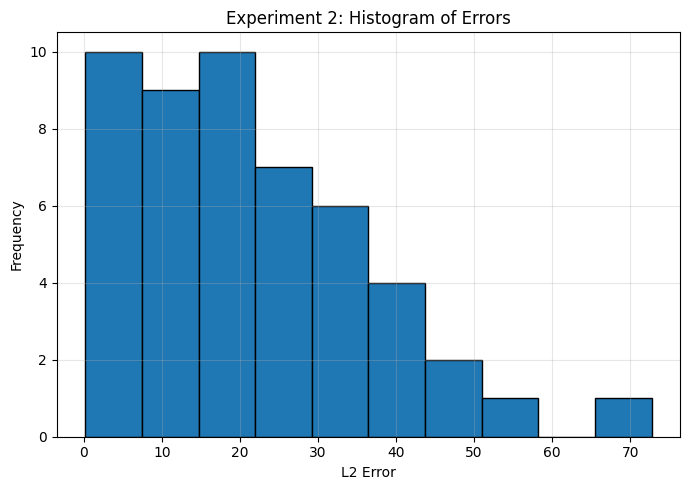

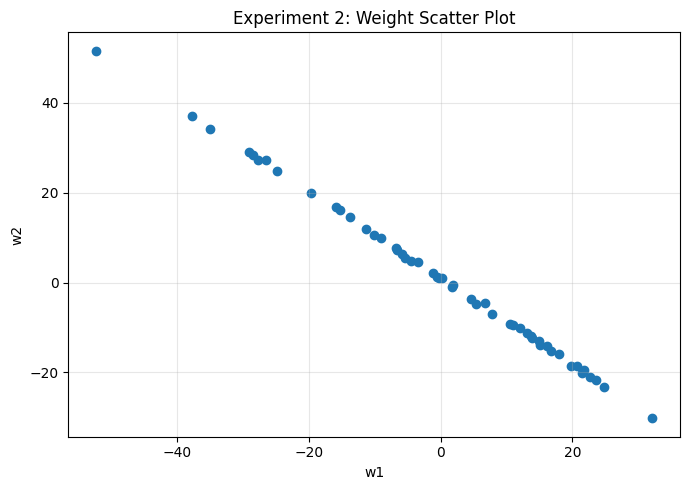

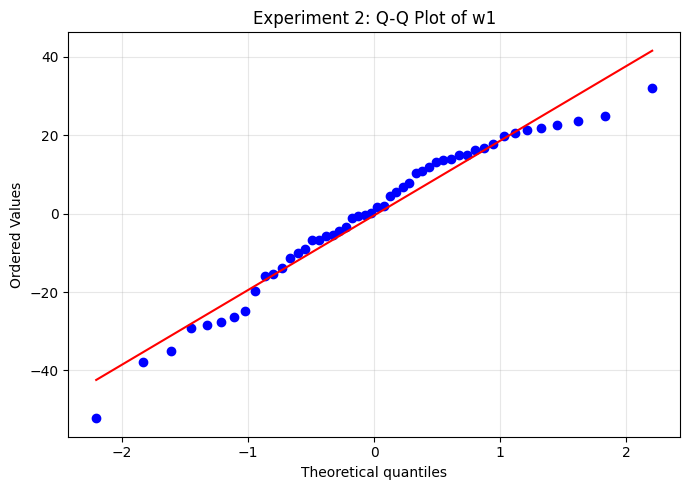

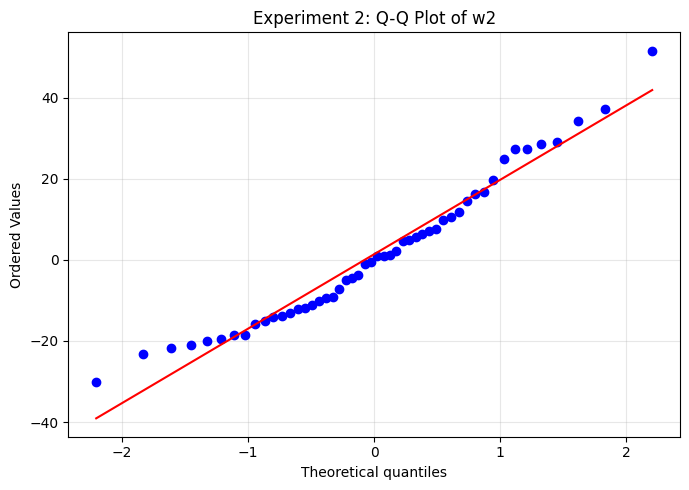

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import probplot

rng = np.random.default_rng(42)
beta = np.array([0, 1])
sigma = 1
n_simulations = 50
X1 = np.array([
    [-1, -1.5],
    [0, 0.5],
    [1, 0.5],
    [2, 1.5]
])
X2 = np.array([
    [-1, -1],
    [0, 0],
    [1, 1],
    [2, 2.1]
])
def experiment(X, name):
    print("\n" + "*" * 20)
    print(name)
    XtX = X.T @ X
    condition_number = np.linalg.cond(XtX)
    theoretical_mean = beta
    theoretical_cov = sigma**2 * np.linalg.inv(XtX)
    print("X.T @ X:")
    print(XtX)
    print("Condition Number:")
    print(condition_number)
    print("Theoretical Mean:")
    print(theoretical_mean)
    print("Theoretical Covariance:")
    print(theoretical_cov)
    weights = []
    errors = []
    for i in range(n_simulations):
        epsilon = rng.normal(0, sigma, size=X.shape[0])
        y = X @ beta + epsilon
        w = np.linalg.solve(XtX, X.T @ y)
        error = np.linalg.norm(w - beta)
        weights.append(w)
        errors.append(error)
    weights = np.array(weights)
    errors = np.array(errors)
    empirical_mean = np.mean(weights, axis=0)
    empirical_cov = np.cov(weights, rowvar=False, ddof=1)
    print("Empirical Mean:")
    print(empirical_mean)
    print("Empirical Covariance:")
    print(empirical_cov)
    print("Mean Error:")
    print(np.mean(errors))
    print("Standard Deviation of Errors:")
    print(np.std(errors, ddof=1))
    print("Correlation between w1 and w2:")
    print(np.corrcoef(weights.T)[0, 1])
    # Histogram of errors
    plt.figure(figsize=(7, 5))
    plt.hist(errors, bins=10, edgecolor="black")
    plt.xlabel("L2 Error")
    plt.ylabel("Frequency")
    plt.title(f"{name}: Histogram of Errors")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    # Scatter plot of weights
    plt.figure(figsize=(7, 5))
    plt.scatter(weights[:, 0], weights[:, 1])
    plt.xlabel("w1")
    plt.ylabel("w2")
    plt.title(f"{name}: Weight Scatter Plot")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    # Q-Q plot for w1
    plt.figure(figsize=(7, 5))
    probplot(weights[:, 0], dist="norm", plot=plt)
    plt.title(f"{name}: Q-Q Plot of w1")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    # Q-Q plot for w2
    plt.figure(figsize=(7, 5))
    probplot(weights[:, 1], dist="norm", plot=plt)
    plt.title(f"{name}: Q-Q Plot of w2")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    return weights, errors


weights1, errors1 = experiment(X1, "Experiment 1")

weights2, errors2 = experiment(X2, "Experiment 2")


Q5)

- Plot the exponential probability density function and visualize the likelihood of observed samples under different parameter values.

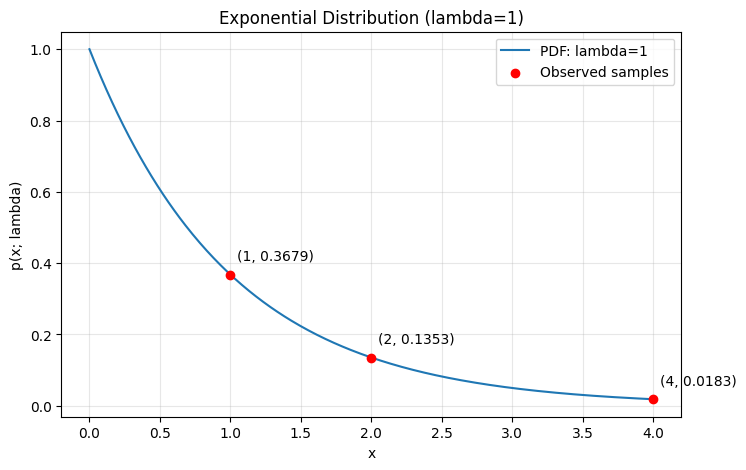

Likelihood for lambda=1: 0.0009118819655545162
Likelihood for lambda=2: 6.652229752828544e-06
MLE of lambda: 0.42857142857142855


In [10]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 4])
lam = 1
def exponential_pdf(x, lam):
    return lam * np.exp(-lam * x)

x = np.linspace(0, 4, 400)
pdf = exponential_pdf(x, lam)
plt.figure(figsize=(8, 5))
plt.plot(x, pdf, label="PDF: lambda=1")
likelihood_values = exponential_pdf(X, lam)
plt.scatter(X, likelihood_values, color="red", label="Observed samples", zorder=3)
for xi, yi in zip(X, likelihood_values):
    plt.annotate(f"({xi}, {yi:.4f})", (xi, yi), xytext=(5, 10), textcoords="offset points")
plt.xlabel("x")
plt.ylabel("p(x; lambda)")
plt.title("Exponential Distribution (lambda=1)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
def likelihood(lam, X):
    return np.prod(lam * np.exp(-lam * X))

L1 = likelihood(1, X)
L2 = likelihood(2, X)
print("Likelihood for lambda=1:", L1)
print("Likelihood for lambda=2:", L2)
lambda_mle = len(X) / np.sum(X)
print("MLE of lambda:", lambda_mle)